In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import mdtraj as md
from scipy.spatial.distance import pdist, squareform
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# Extra packages for this notebook:  pip install igraph h5py huggingface_hub
import igraph as ig

In [ ]:
# pip install igraph h5py huggingface_hub

  Using cached igraph-1.0.0-cp39-abi3-win_amd64.whl.metadata (4.5 kB)
  Using cached h5py-3.16.0-cp312-cp312-win_amd64.whl.metadata (3.1 kB)
  Using cached huggingface_hub-2.4.0-py3-none-any.whl.metadata (16 kB)
  Using cached hf_xet-1.8.0-cp38-abi3-win_amd64.whl.metadata (4.9 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached truststore-0.10.5-py3-none-any.whl.metadata (4.5 kB)
Using cached igraph-1.0.0-cp39-abi3-win_amd64.whl (3.2 MB)
Using cached h5py-3.16.0-cp312-cp312-win_amd64.whl (3.2 MB)
Using cached huggingface_hub-2.4.0-py3-none-any.whl (857 kB)
Using cached hf_xet-1.8.0-cp38-abi3-win_amd64.whl (3.9 MB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)
Using cached truststore-0.10.5-py3-none-any.whl (19 kB)

   ------ ---------------------------------  2/12 [tqdm]
   ------ ---------------------------------  2/12 [tqdm]
   ------ ---------------------------------  2/12 [tqdm]
   ------ ---------------------------------  2/12 [tqdm]
   ---------- -

## Settings

Same choices as in the first notebook: every 5th frame, contacts below 8 Å, and windows of 20 frames (1 ns) with 0.8 overlap.

In [ ]:
PROTEINS = ["1a62_A", "16pk_A", "1k5n_A"]

STRIDE = 5                  # every 5th frame -> ~2000 frames over 100 ns
CONTACT_THRESHOLD = 8.0     # Å
WIDTH, OVERLAP = 20, 0.8    # sliding window: 20 frames (1 ns), 80% overlap
RANDOM_STATE = 42


def file_paths(protein):
    folder = f"{protein}_protein"
    return f"{folder}/{protein}.pdb", f"{folder}/{protein}_prod_R1_fit.xtc"

## Helper functions

The same helpers as in the first notebook, collected in one cell:

- `load_ca`: load a trajectory, keep the CA atoms, coordinates in Å.
- `contact_table`: one row per frame, one column per residue pair (True = contact).
- `window_mean`: average any per-frame array over sliding windows.
- `plot_projection`: scatter plot of a 2D projection, with lines between consecutive points.

In [ ]:
def load_ca(protein, stride=STRIDE):
    pdb, xtc = file_paths(protein)
    traj = md.load(xtc, top=pdb, stride=stride)
    traj = traj.atom_slice(traj.topology.select("name CA"))
    return {"traj": traj, "coords": traj.xyz * 10, "time_ns": traj.time / 1000}


def contact_table(coords, threshold=CONTACT_THRESHOLD):
    """(frames, residue pairs) boolean table; column order = np.triu_indices(N, k=1)."""
    return np.array([pdist(frame) < threshold for frame in coords])


def step_for(width, overlap):
    return max(1, int(round(width * (1 - overlap))))


STEP = step_for(WIDTH, OVERLAP)


def window_mean(values, width=WIDTH, step=STEP):
    starts = np.arange(0, len(values) - width + 1, step)
    return np.array([values[s:s + width].mean(axis=0) for s in starts])


def plot_projection(ax, Y, colour, title, colour_label, connect=True, cmap="viridis"):
    if connect:
        ax.plot(Y[:, 0], Y[:, 1], lw=0.3, c="gray", alpha=0.6, zorder=1)
    sc = ax.scatter(Y[:, 0], Y[:, 1], c=colour, s=4, zorder=2, cmap=cmap)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(sc, ax=ax, label=colour_label)


def varying_columns(X):
    """Columns whose value changes at least once (constant columns carry no information)."""
    if X.dtype == bool:
        return X.any(axis=0) & ~X.all(axis=0)
    return X.std(axis=0) > 0


def changing_contacts(coords, threshold=CONTACT_THRESHOLD):
    """Contact table with only the contacts that change, as float (keeps memory low for big proteins)."""
    C = contact_table(coords, threshold)
    return C[:, varying_columns(C)].astype(np.float32)

In [ ]:
data = {}
for p in PROTEINS:
    if not os.path.exists(file_paths(p)[1]):
        print(f"{p}: files not found, skipped")
        continue
    data[p] = load_ca(p)
    M, N, _ = data[p]["coords"].shape
    print(f"{p}: {M} frames, {N} residues")

1a62_A: 2001 frames, 130 residues
16pk_A: 2001 frames, 415 residues
1k5n_A: 2001 frames, 276 residues


## 1. Centrality vectors

### The idea

So far, each frame was described by **one value per residue pair** (contact or no contact): 8,385 columns for 1a62_A.
Here, each frame is described by **one value per residue**: how central that residue is in the frame's contact network.
That gives one column per residue (130 for 1a62_A), so frame *t* becomes the vector

  **v**(t) = (centrality of residue 0, centrality of residue 1, …, centrality of residue N−1).

Then the same steps as before: windows, PCA and t-SNE, time vs. PC1.

### Four centralities

| Centrality | What it measures for a residue | In protein terms |
| --- | --- | --- |
| **Degree** | Number of contacts | How buried/packed the residue is |
| **Closeness** | 1 / average shortest-path length to all other residues | How close it is to the "middle" of the network |
| **Betweenness** | How many shortest paths between other residues pass through it | Whether it is a bridge, e.g. a hinge between domains |
| **Eigenvector** | High if its neighbours are themselves central | Whether it sits in a densely connected core |

In [ ]:
# handles one frame and gives 4 centrality measures for every residue
def frame_centralities(frame_coords, threshold=CONTACT_THRESHOLD):
    """Degree, closeness, betweenness and eigenvector centrality of every residue in one frame."""
    # contact map, adjacency matrix
    N = len(frame_coords)
    A = squareform(pdist(frame_coords) < threshold)          # N x N adjacency, no self-loops
    # turn grid into graph and compute centralities
    # keep only the upper half, list positions of all True cells
    i, j = np.nonzero(np.triu(A, k=1))
    # build a network
    g = ig.Graph(n=N, edges=list(zip(i.tolist(), j.tolist())))
    return {
        "degree": A.sum(axis=1).astype(float),
        "closeness": np.nan_to_num(np.array(g.closeness(), dtype=float)),
        "betweenness": np.array(g.betweenness(), dtype=float),
        "eigenvector": np.array(g.eigenvector_centrality(), dtype=float),
    }

CENTRALITIES = ["degree", "closeness", "betweenness", "eigenvector"]

# all frames -> one table per centrality
def centrality_vectors(coords, threshold=CONTACT_THRESHOLD):
    """dict: centrality name -> (frames, residues) array."""
    per_frame = [frame_centralities(f, threshold) for f in coords]
    return {c: np.array([fc[c] for fc in per_frame]) for c in CENTRALITIES}


cent = {}
for p in data:
    cent[p] = centrality_vectors(data[p]["coords"])
    print(f"{p}: centrality vectors, shape {cent[p]['degree'].shape} (frames, residues)")

1a62_A: centrality vectors, shape (2001, 130) (frames, residues)
16pk_A: centrality vectors, shape (2001, 415) (frames, residues)
1k5n_A: centrality vectors, shape (2001, 276) (frames, residues)


In [ ]:
cent[p]

{'degree': array([[ 4., 10., 13., ...,  9.,  6.,  7.],
        [ 4.,  9., 12., ...,  9.,  6.,  7.],
        [ 4.,  9., 12., ..., 10.,  6.,  5.],
        ...,
        [ 4.,  9., 13., ..., 10.,  6.,  5.],
        [ 4., 10., 12., ...,  9.,  6.,  5.],
        [ 4., 10., 13., ...,  9.,  6.,  5.]], shape=(2001, 415)),
 'closeness': array([[0.15723509, 0.18318584, 0.1730046 , ..., 0.17157066, 0.16573259,
         0.16096423],
        [0.14330218, 0.1656    , 0.16700282, ..., 0.16409037, 0.15693707,
         0.15640348],
        [0.14440181, 0.16700282, 0.16849817, ..., 0.16911765, 0.15849923,
         0.14603175],
        ...,
        [0.14623808, 0.16939444, 0.17100372, ..., 0.17722603, 0.1622893 ,
         0.15546376],
        [0.14945848, 0.17409588, 0.16911765, ..., 0.16573259, 0.15599096,
         0.15159282],
        [0.15209405, 0.17609528, 0.17121588, ..., 0.16613162, 0.16121495,
         0.15367483]], shape=(2001, 415)),
 'betweenness': array([[  0.        , 574.32381427, 406.1806689

### Projections: edge vector vs. centrality vectors

Rows: the edge vector from the first notebook (baseline), then the four centralities.
Columns: PCA, t-SNE, and time vs. PC1. All use the same windows (1 ns, 0.8 overlap).

**Scaling.** Within one centrality, all columns have the same unit, so no normalization is needed (as for the edge vector).
Set `SCALE = True` to z-score each residue's column instead; residues whose centrality barely changes then get as much weight as the others.

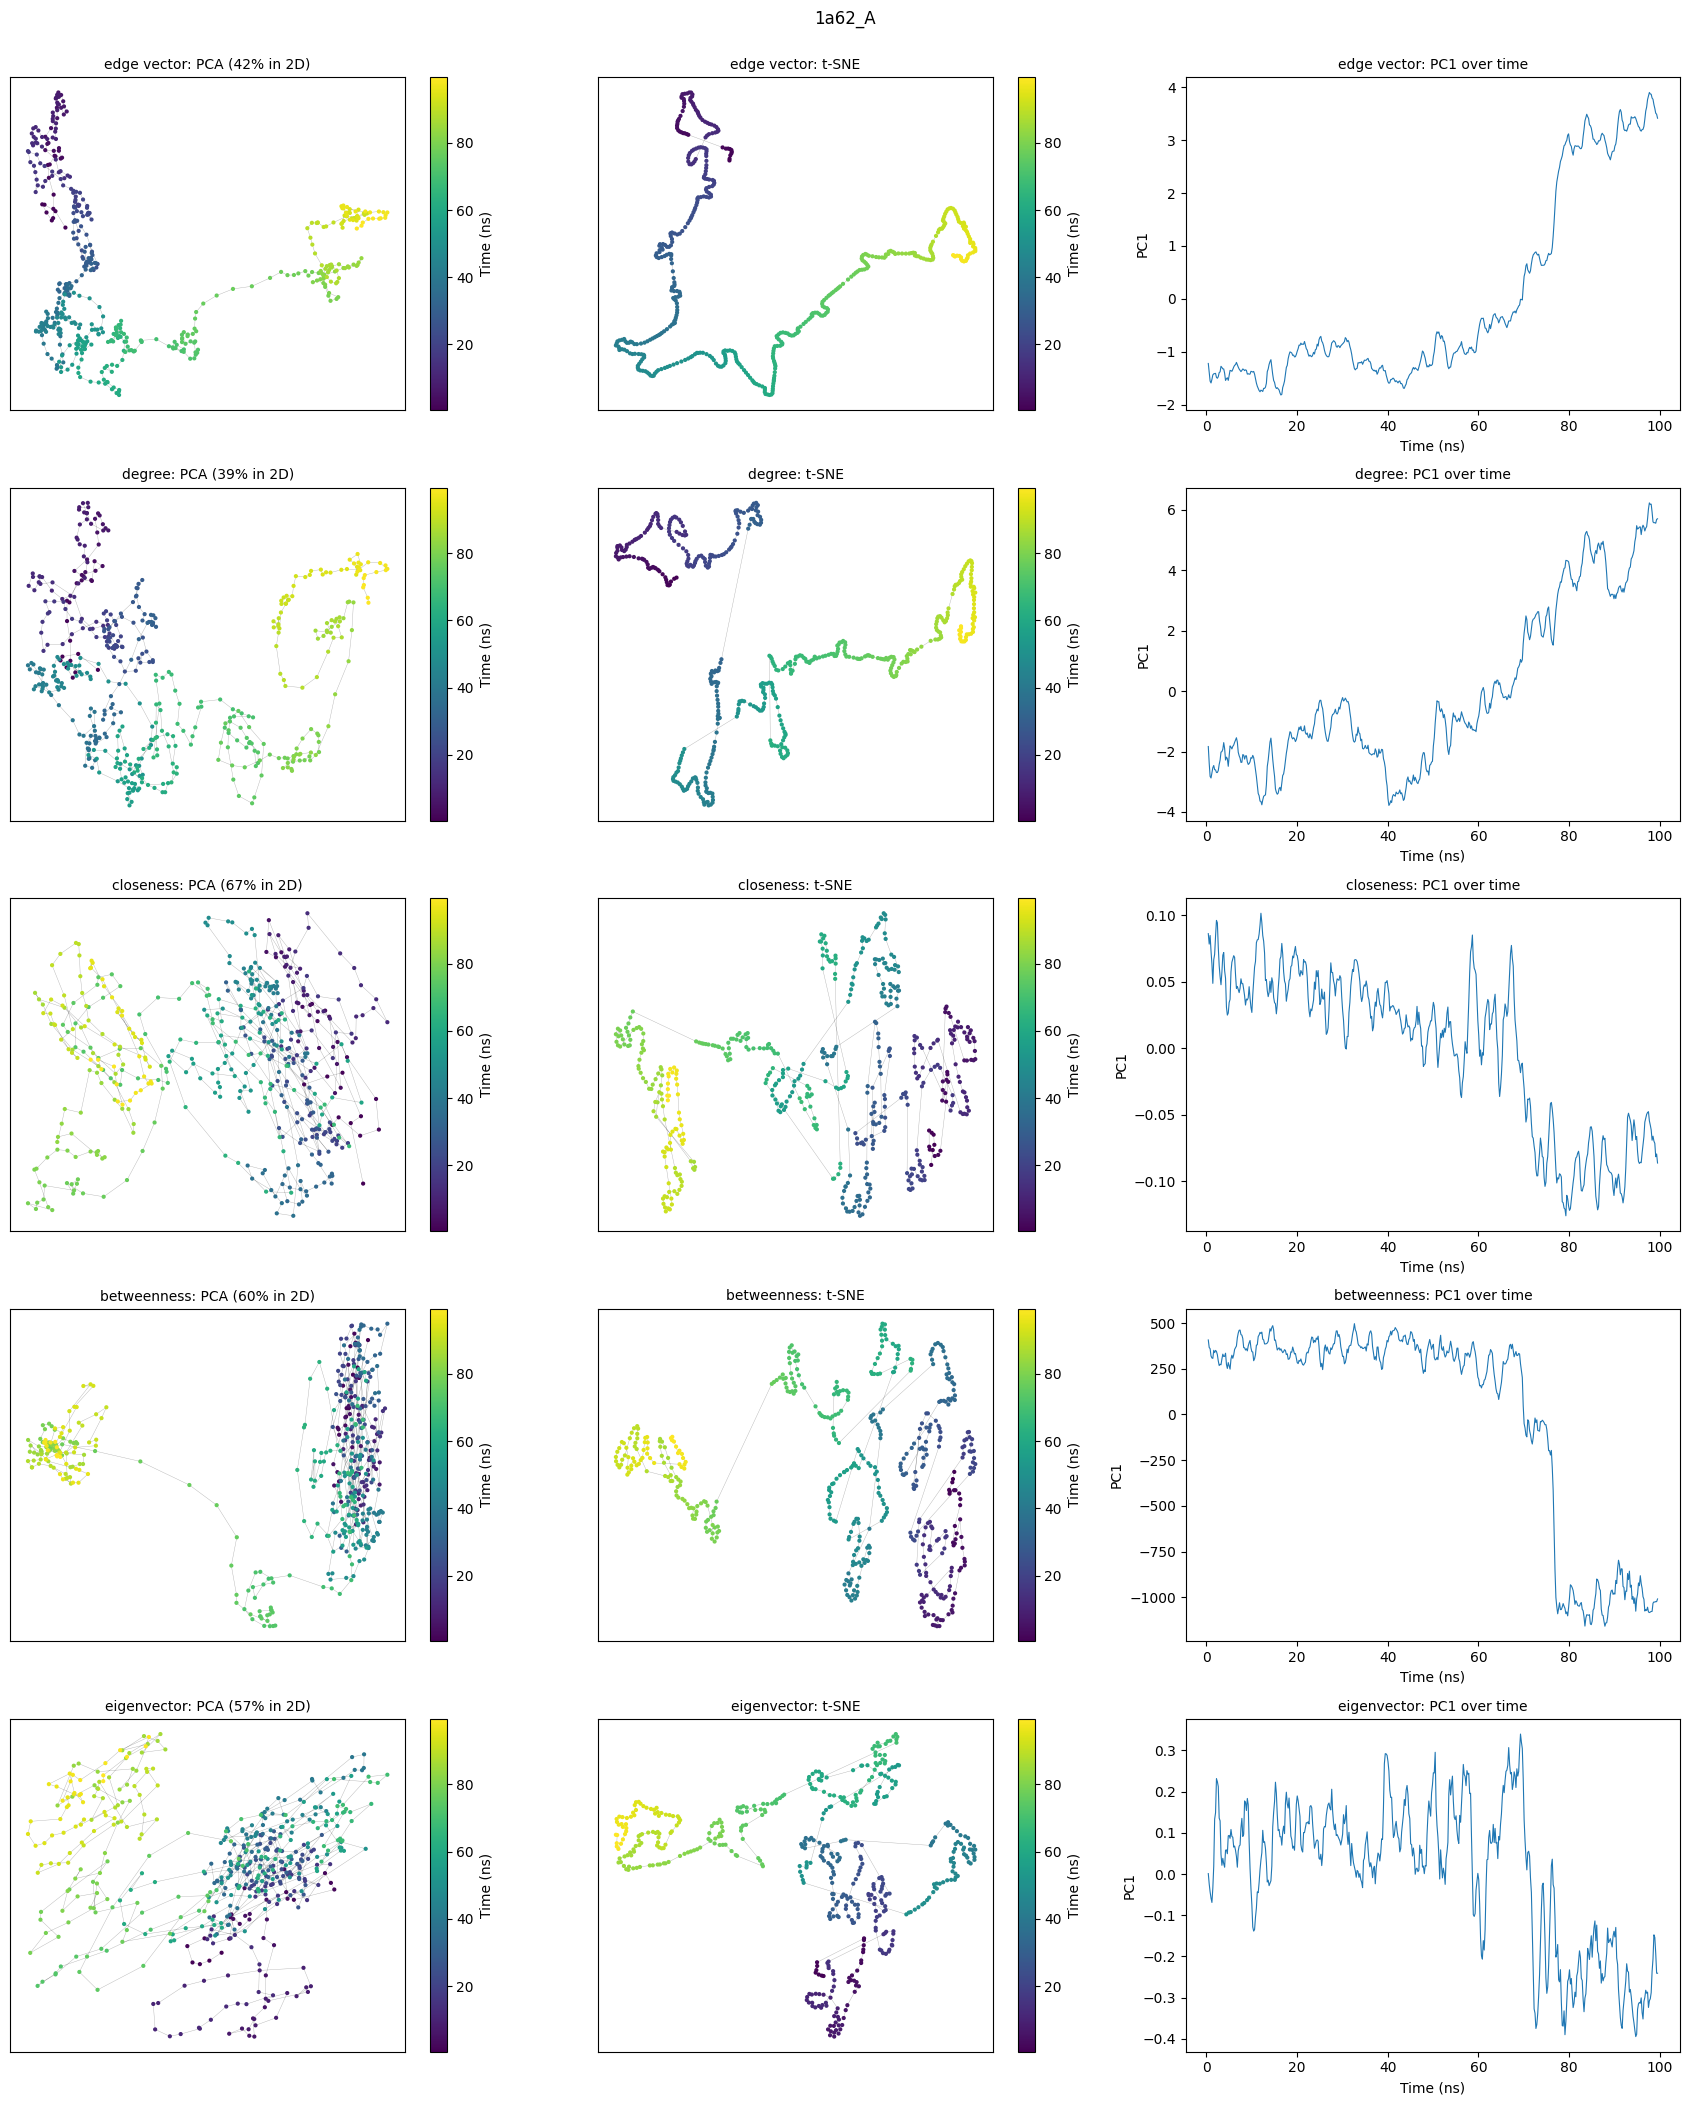

In [ ]:
PROTEIN = "1a62_A"
SCALE = False

# collects five tables for one protein: edge vector + the four centralities
# each goes through a sliding window (20 frames, 80% overlap)
def representations(p):
    """Windowed feature tables for one protein: edge vector + the four centralities."""
    reps = {"edge vector": window_mean(changing_contacts(data[p]["coords"]))}
    for c in CENTRALITIES:
        reps[c] = window_mean(cent[p][c])
    return reps

# drop cols that never change
# optional scaling (StandardScaler) to mean=0, std=1. false for now
# PCA and t-SNE to 2D
def project(X, scale=SCALE, tsne=True):
    X = X[:, varying_columns(X)]
    if scale:
        X = StandardScaler().fit_transform(X)
    pca = PCA(n_components=2).fit(X)
    out = {"pca": pca.transform(X), "var": pca.explained_variance_ratio_, "components": pca.components_}
    if tsne:
        out["tsne"] = TSNE(n_components=2, perplexity=30, init="pca",
                           random_state=RANDOM_STATE).fit_transform(X)
    return out

reps = representations(PROTEIN)
tW = window_mean(data[PROTEIN]["time_ns"])
proj = {name: project(X) for name, X in reps.items()}

fig, axes = plt.subplots(len(reps), 3, figsize=(17, 4.2 * len(reps)))
for row, (name, P) in zip(axes, proj.items()):
    plot_projection(row[0], P["pca"], tW, f"{name}: PCA ({P['var'].sum():.0%} in 2D)", "Time (ns)")
    plot_projection(row[1], P["tsne"], tW, f"{name}: t-SNE", "Time (ns)")
    row[2].plot(tW, P["pca"][:, 0], lw=0.8)
    row[2].set_title(f"{name}: PC1 over time", fontsize=10)
    row[2].set_xlabel("Time (ns)"); row[2].set_ylabel("PC1")
fig.suptitle(PROTEIN, y=1.0)
plt.tight_layout()
plt.show()

betweeenness: 
During 0–70 ns, betweenness doesn’t drift. The colours mix in one cluster, while the edge vector shows a slow drift through that period. So the gradual changes in contacts during the first 70 ns don’t change which residues act as bridges; they’re local changes. Betweenness only reacts when the network’s path structure changes.
The switch has two steps: a first one at about 70 ns and the main one at about 77 ns. The heatmap below shows what happens in between.

The centralities explain more variance in 2D (closeness 67%, betweenness 60%, eigenvector 57%) than the edge vector (42%) or degree (39%). That’s mostly because they have far fewer columns (130, not 439), many of which move together. It isn’t a quality score in itself; betweenness happens to also look the cleanest, but closeness explains the most variance and looks the noisiest.

In [ ]:
rows = []
for p in data:
    reps = {"edge vector": contact_table(data[p]["coords"])}          # all residue pairs, per frame
    reps.update({c: cent[p][c] for c in CENTRALITIES})                  # all residues, per frame
    for name, X in reps.items():
        n_total = X.shape[1]
        n_const_frames = (~varying_columns(X)).sum()                    # constant over all frames
        W = window_mean(X.astype(np.float32))
        n_const_windows = (~varying_columns(W)).sum()                   # constant over all windows
        rows.append({"protein": p, "representation": name, "columns": n_total,
                     "constant (frames)": n_const_frames, "constant (windows)": n_const_windows,
                     "% removed": round(100 * n_const_windows / n_total, 1)})

import pandas as pd
pd.DataFrame(rows)

,protein,representation,columns,constant (frames),constant (windows),% removed
0,1a62_A,edge vector,8385,7946,7946,94.8
1,1a62_A,degree,130,0,0,0.0
2,1a62_A,closeness,130,0,0,0.0
3,1a62_A,betweenness,130,0,0,0.0
4,1a62_A,eigenvector,130,0,0,0.0
5,16pk_A,edge vector,85905,84574,84574,98.5
6,16pk_A,degree,415,4,4,1.0
7,16pk_A,closeness,415,0,0,0.0
8,16pk_A,betweenness,415,0,0,0.0
9,16pk_A,eigenvector,415,0,0,0.0


- Edge vector: 95–98.5% of columns are constant and get dropped. For the bigger proteins, even more are constant (98.5% for 16pk_A), because most residue pairs are far apart and never touch.
- Closeness, betweenness and eigenvector: nothing removed for any protein. Every residue’s value changes at least a little.
- Degree: only 4 residues in 16pk_A and 1 in 1k5n_A are constant. Their contact count never changes in any frame, probably residues in a very stable part of the structure.

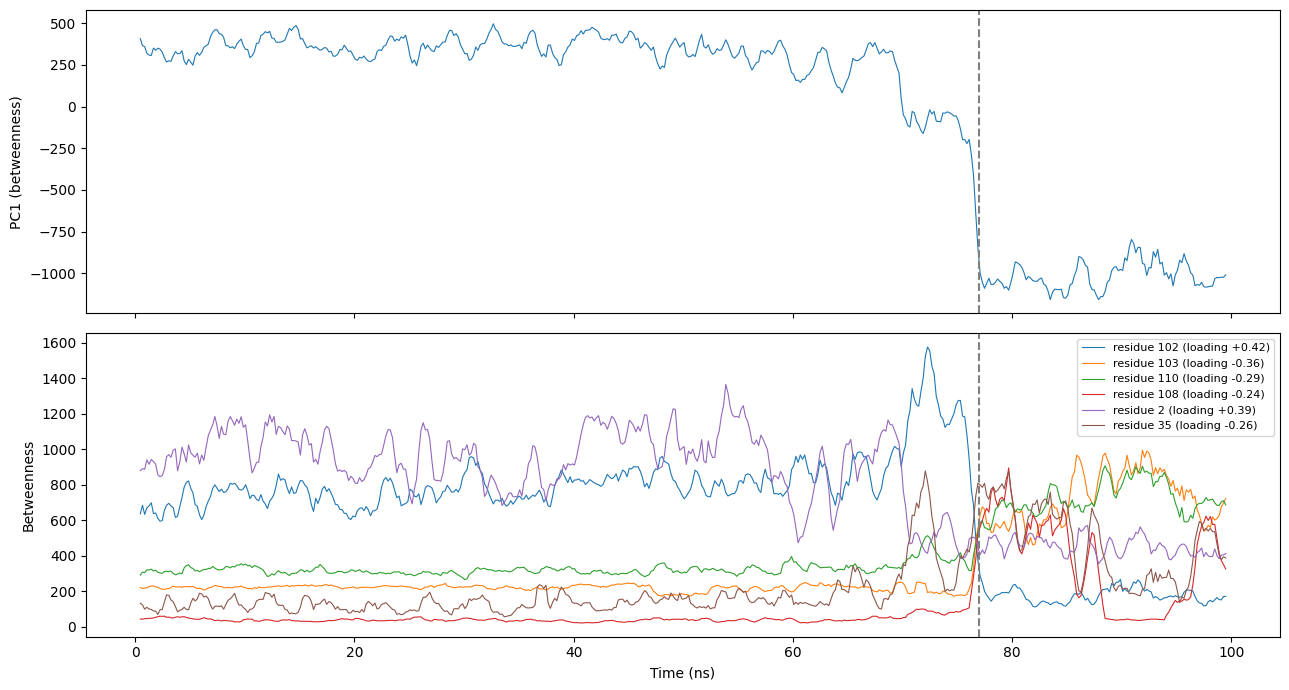

PC1 falls at the switch

residue 102: before     816, after     176, change    -640, loading +0.42 -> consistent
residue 103: before     221, after     739, change    +519, loading -0.36 -> consistent
residue 110: before     325, after     735, change    +411, loading -0.29 -> consistent
residue 108: before      42, after     331, change    +289, loading -0.24 -> consistent
residue   2: before     942, after     453, change    -489, loading +0.39 -> consistent
residue  35: before     164, after     440, change    +276, loading -0.26 -> consistent


In [ ]:
p = "1a62_A"
RESIDUES = [102, 103, 110, 108, 2, 35]   # top residues from the loadings printout
SWITCH = 77                              # ns

t = window_mean(data[p]["time_ns"])
B = window_mean(cent[p]["betweenness"])          # windows x residues
pca = PCA(n_components=1).fit(B)
pc1 = pca.transform(B)[:, 0]
loadings = pca.components_[0]

# 1. PC1 and the residues' betweenness over time
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(t, pc1, lw=0.8)
axes[0].set_ylabel("PC1 (betweenness)")
for r in RESIDUES:
    axes[1].plot(t, B[:, r], lw=0.8, label=f"residue {r} (loading {loadings[r]:+.2f})")
axes[1].set_ylabel("Betweenness"); axes[1].set_xlabel("Time (ns)"); axes[1].legend(fontsize=8)
for ax in axes:
    ax.axvline(SWITCH, ls="--", c="gray")
plt.tight_layout(); plt.show()

# 2. Before vs. after the switch
before = B[t < SWITCH - 2].mean(axis=0)
after = B[t > SWITCH + 2].mean(axis=0)
pc1_falls = pc1[t > SWITCH + 2].mean() < pc1[t < SWITCH - 2].mean()
print(f"PC1 {'falls' if pc1_falls else 'rises'} at the switch\n")
for r in RESIDUES:
    change = after[r] - before[r]
    expected = -np.sign(loadings[r]) if pc1_falls else np.sign(loadings[r])   # direction the loading predicts
    ok = "consistent" if np.sign(change) == expected else "NOT consistent"
    print(f"residue {r:>3}: before {before[r]:7.0f}, after {after[r]:7.0f}, change {change:+7.0f}, "
          f"loading {loadings[r]:+.2f} -> {ok}")

### Time vs. PC1 for every protein and representation

PC1 is scaled to mean 0 and standard deviation 1 per line, so the shapes can be compared (the sign of PC1 is arbitrary, so a line may be upside down).
Matching jumps across representations mean they detect the same transition.

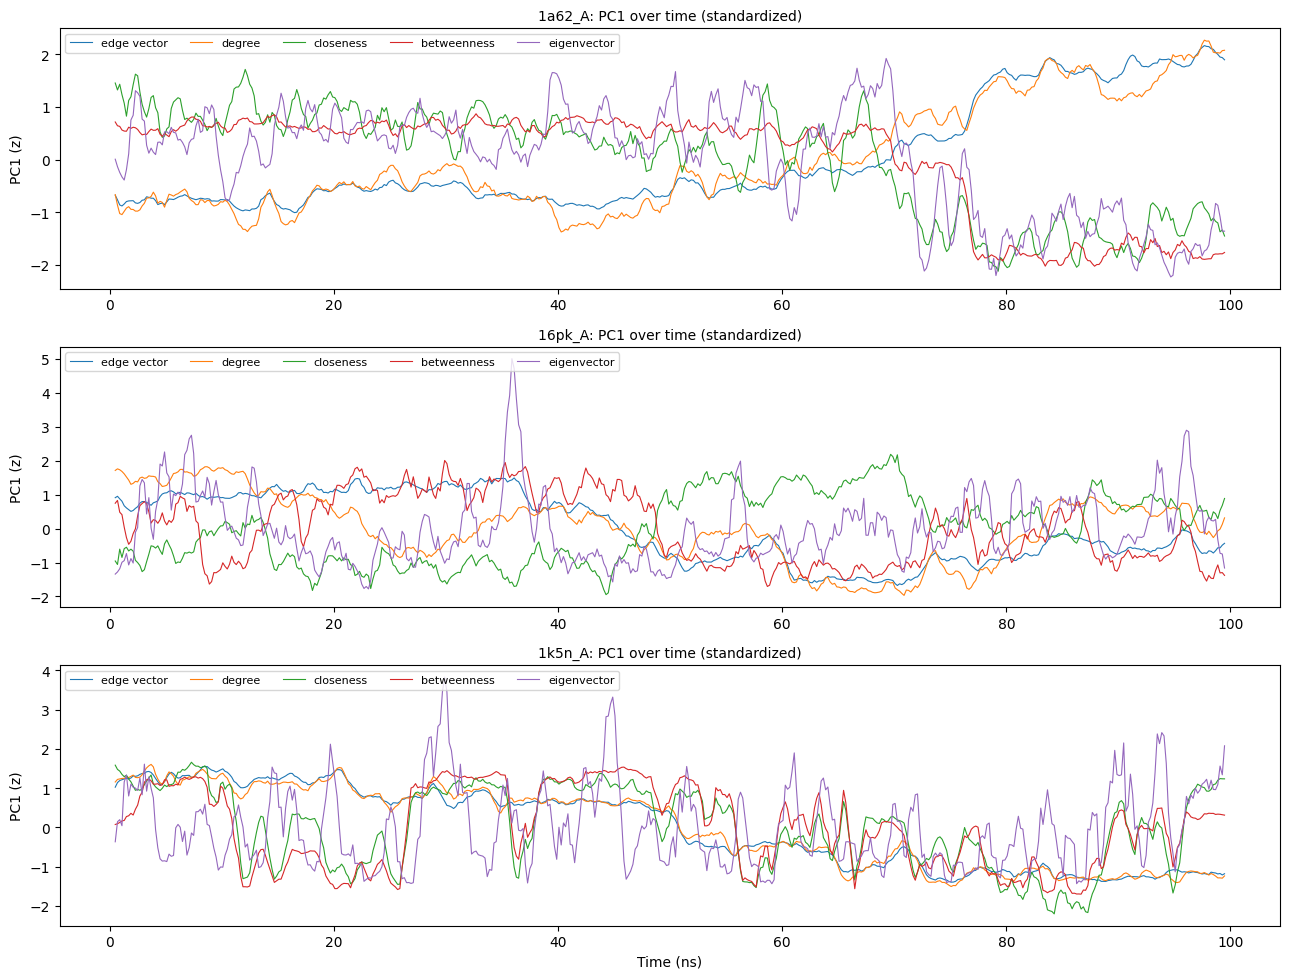

In [ ]:
fig, axes = plt.subplots(len(data), 1, figsize=(13, 3.3 * len(data)), squeeze=False)
for ax, p in zip(axes[:, 0], data):
    t = window_mean(data[p]["time_ns"])
    for name, X in representations(p).items():
        pc1 = project(X, tsne=False)["pca"][:, 0]
        ax.plot(t, (pc1 - pc1.mean()) / pc1.std(), lw=0.8, label=name)
    ax.set_title(f"{p}: PC1 over time (standardized)", fontsize=10)
    ax.set_ylabel("PC1 (z)")
    ax.legend(fontsize=8, ncol=5, loc="upper left")
axes[-1, 0].set_xlabel("Time (ns)")
plt.tight_layout()
plt.show()

### Which residues change? Centrality over time

The advantage of one value per residue: you can draw the whole feature table as an image.
Each row is a residue, each column a window in time, colour = centrality. Horizontal bands that change colour at some time point are residues whose role changes.

Below each heatmap, the **PC1 loadings**: how strongly each residue's centrality drives PC1. Tall bars (positive or negative) mark the residues that separate the states along PC1.

degree: residues with the largest PC1 loadings: 89 (+0.32), 109 (-0.30), 111 (-0.27), 126 (-0.27), 102 (-0.26), 2 (-0.24), 122 (-0.23), 39 (+0.21), 38 (-0.20), 88 (+0.18)
betweenness: residues with the largest PC1 loadings: 102 (+0.42), 2 (+0.39), 103 (-0.36), 110 (-0.29), 35 (-0.26), 108 (-0.24), 31 (+0.23), 76 (+0.20), 111 (+0.19), 3 (-0.17)


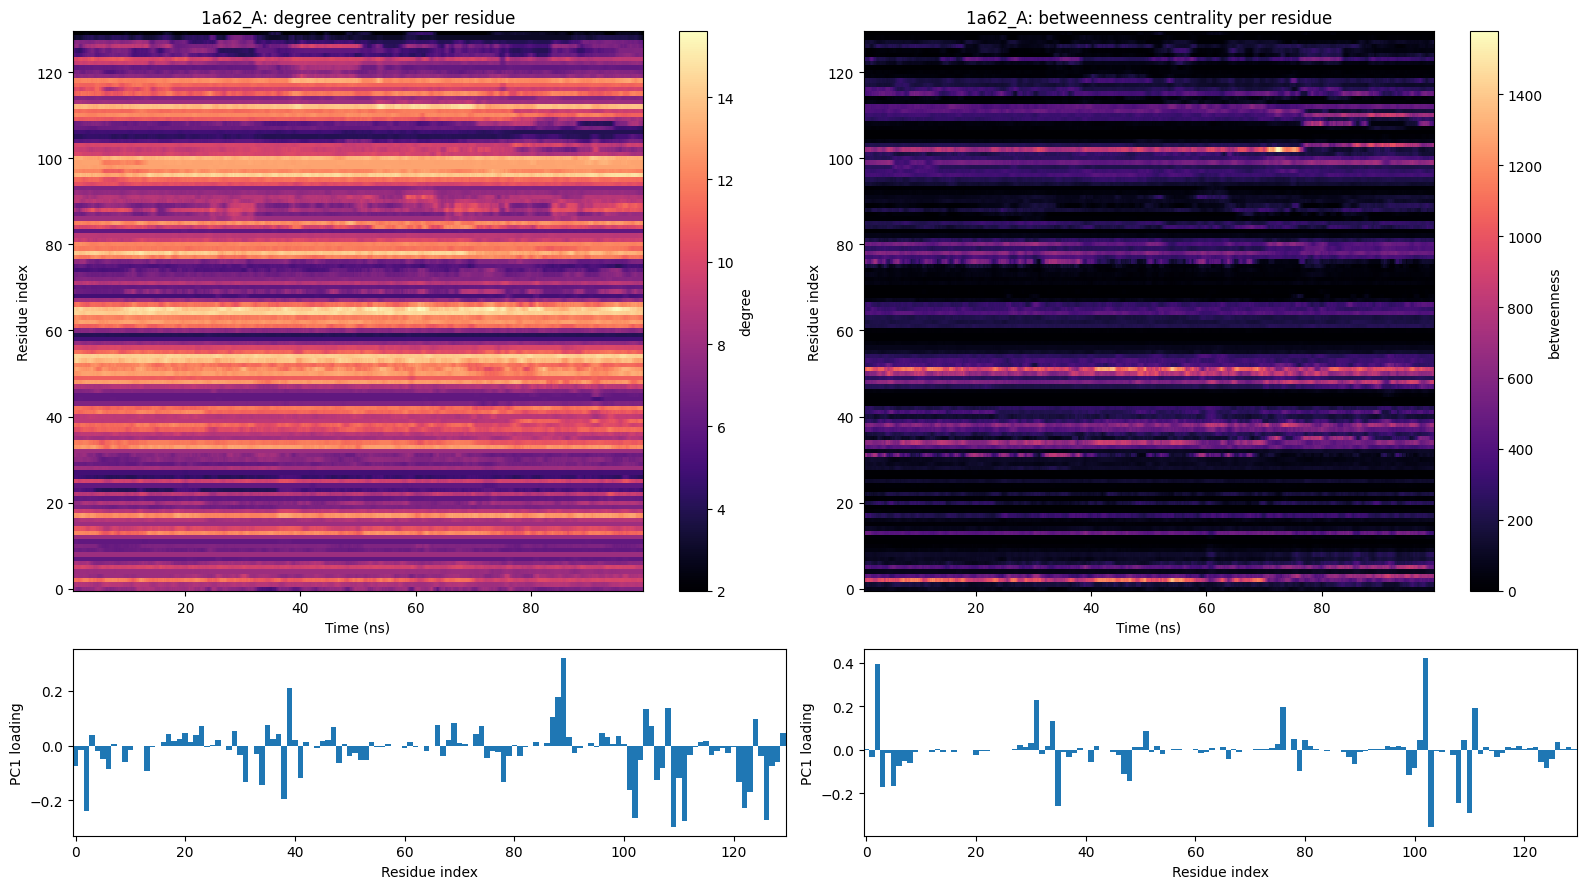

In [ ]:
SHOW = ["degree", "betweenness"]
TOP = 10

p = PROTEIN
t = window_mean(data[p]["time_ns"])
fig, axes = plt.subplots(2, len(SHOW), figsize=(8 * len(SHOW), 9),
                         gridspec_kw={"height_ratios": [3, 1]}, squeeze=False)
for col, c in enumerate(SHOW):
    X = window_mean(cent[p][c])
    N = X.shape[1]
    # each pixel's color is that residue's centrality at that time window
    im = axes[0, col].imshow(X.T, aspect="auto", origin="lower", cmap="magma",
                             extent=[t[0], t[-1], -0.5, N - 0.5], interpolation="nearest")
    axes[0, col].set_title(f"{p}: {c} centrality per residue")
    axes[0, col].set_xlabel("Time (ns)"); axes[0, col].set_ylabel("Residue index")
    plt.colorbar(im, ax=axes[0, col], label=c)

    loadings = np.zeros(N)
    keep = varying_columns(X)
    # PCA on the residues that change, then put the loadings back into a full-length array
    loadings[keep] = PCA(n_components=1).fit(X[:, keep]).components_[0]
    axes[1, col].bar(np.arange(N), loadings, width=1.0)
    axes[1, col].set_xlim(-0.5, N - 0.5)
    axes[1, col].set_xlabel("Residue index"); axes[1, col].set_ylabel("PC1 loading")
    top = np.argsort(-np.abs(loadings))[:TOP]
    print(f"{c}: residues with the largest PC1 loadings:",
          ", ".join(f"{r} ({loadings[r]:+.2f})" for r in top))
plt.tight_layout()
plt.show()

1. Degree carries about the same information as the edge vector, summed per residue: it shows gradual change plus the switch, and its loadings point to the same residues as your contact analysis.
2. Betweenness gives the cleanest picture of 1a62_A: one stable state from 0 to ~70 ns, a two-step transition (~70 and ~77 ns) and a second stable state. The heatmap and loadings show which residues change role: 102 is the bridge during the transition, and 103 and 108–110 take over afterwards.
3. Closeness and eigenvector detect the switch but are too noisy, especially eigenvector, which spikes in all three proteins.
4. For 1k5n_A, betweenness and closeness catch the between-part events (α3 at 15–30 ns, the new interface at the end) that the edge vector underplays. For 16pk_A, no representation shows one clear event, consistent with its two domains changing at different times.
5. New leads to check: residues 88–89 (gaining contacts) and 76 (losing its bridge role) in 1a62_A, which didn’t show up in the earlier analysis. The nglview cell from part 1, with these residues highlighted, would show what they do.

## 2. A bigger and more varied dataset: mdCATH

### Why mdCATH

ATLAS simulations are short (100 ns) and run at room temperature, starting from the folded structure, so the proteins mostly fluctuate around one shape.
**mdCATH** ([Mirarchi et al. 2024](https://arxiv.org/abs/2407.14794)) has:

- 5,398 protein domains (50–500 residues),
- each simulated at **five temperatures: 320, 348, 379, 413 and 450 K**, with five replicas per temperature,
- mostly **500 ns** per trajectory, one frame per ns.

At 413 K and especially 450 K many domains partly or fully unfold, so one domain gives you trajectories ranging from "stable" to "unfolding". That is the variation ATLAS lacks.

### How the data is stored

One HDF5 file per domain, downloaded from Hugging Face (about 0.6 GB per domain on average, covering all 25 trajectories). Inside:
`<domain>/pdbProteinAtoms` (the structure), and `<domain>/<temperature>/<replica>/coords` with shape (frames, atoms, 3) in Å.

### What the cells below do

1. Download one domain (or reuse a downloaded file).
2. Load one replica at several temperatures and keep the CA atoms.
3. Put **all temperatures into one shared projection**, so you can see whether high-temperature runs move away from the folded region, and whether different temperatures visit the same states.

The default domain, `5sicI00`, is the example in the mdCATH paper that stays folded at lower temperatures and unfolds at 450 K. Any other domain ID from the dataset works the same way.

An mdCATH file is an HDF5 file: a container organised like folders inside one file:

5sicI00/
├── pdbProteinAtoms      ← the structure, as PDB text
├── 320/                 ← temperature
│   ├── 0/coords         ← replica 0: (frames × atoms × 3), in Å
│   ├── 1/coords
│   └── …
├── 348/ …
└── 450/ …

In [ ]:
import h5py
from huggingface_hub import hf_hub_download

MDCATH_DOMAIN = "5sicI00"
TEMPERATURES = [320, 379, 413, 450]   # choose from 320, 348, 379, 413, 450
REPLICA = 0                           # 0-4
MDCATH_DIR = "mdcath"

# find or downdload
def mdcath_file(domain):
    local = os.path.join(MDCATH_DIR, "data", f"mdcath_dataset_{domain}.h5")
    if os.path.exists(local):
        return local
    return hf_hub_download(repo_id="compsciencelab/mdCATH", filename=f"mdcath_dataset_{domain}.h5",
                           subfolder="data", local_dir=MDCATH_DIR, repo_type="dataset")

# read the file
def load_mdcath(domain, temperatures, replica=0):
    """CA coordinates (Å) per temperature: dict T -> {"coords", "time_ns"}; plus the CA topology."""
    path = mdcath_file(domain)
    with h5py.File(path, "r") as f:
        g = f[domain]
        pdb_text = g["pdbProteinAtoms"][()]
        pdb_text = pdb_text.decode() if isinstance(pdb_text, bytes) else str(pdb_text)
        tmp = os.path.join(MDCATH_DIR, f"{domain}_protein.pdb")
        with open(tmp, "w") as out:
            out.write(pdb_text)
        top = md.load_pdb(tmp).topology
        # find CA atoms
        ca = top.select("name CA")
        runs = {}
        # for each temp, reads coords and keep only teh CA atoms
        for T in temperatures:
            coords = g[str(T)][str(replica)]["coords"][:]          # (frames, atoms, 3), Å
            if coords.shape[1] != top.n_atoms:
                raise ValueError(f"{T} K: {coords.shape[1]} atoms in coords, {top.n_atoms} in the structure")
            runs[T] = {"coords": coords[:, ca], "time_ns": np.arange(len(coords), dtype=float)}  # 1 frame per ns
    return runs, top.subset(ca)


runs, mdcath_top = load_mdcath(MDCATH_DOMAIN, TEMPERATURES, REPLICA)
for T, r in runs.items():
    print(f"{MDCATH_DOMAIN} {T} K: {r['coords'].shape[0]} frames, {r['coords'].shape[1]} residues")

c:\Users\bella\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


5sicI00 320 K: 500 frames, 107 residues
5sicI00 379 K: 130 frames, 107 residues
5sicI00 413 K: 500 frames, 107 residues
5sicI00 450 K: 500 frames, 107 residues


### Sanity check: RMSD and radius of gyration per temperature

Before projecting, check that the temperatures really differ. RMSD to the first frame shows how far the structure moves; the radius of gyration shows how compact it is (it grows when the protein unfolds).

- RMSD to frame 0: how far the structure has moved from its start. It isn’t aligned here: mdCATH files aren’t pre-fitted, so overall rotation adds to it. That’s fine for a rough check.
- Radius of gyration: the average distance of the residues from the protein’s centre, i.e. how spread out it is. A folded protein is compact. If it unfolds, this number grows.

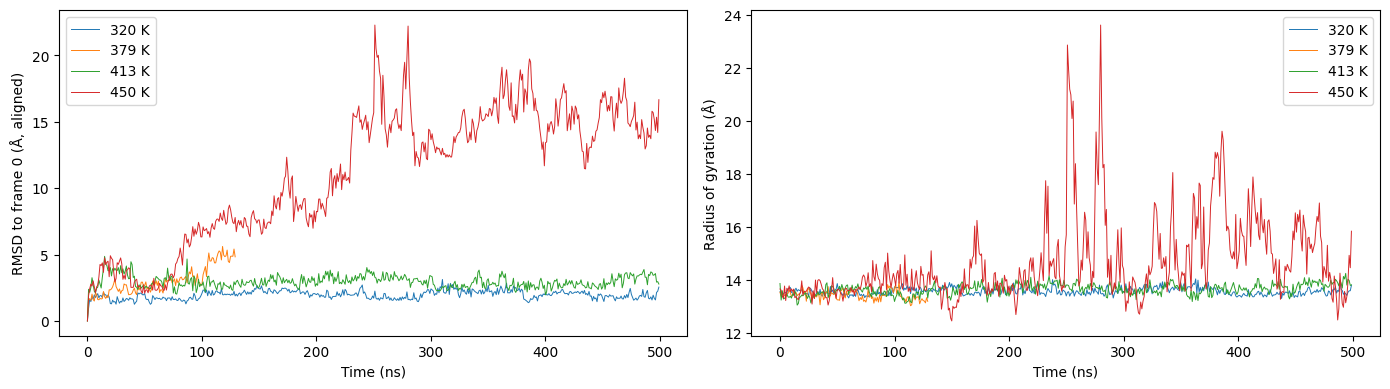

In [ ]:
# check that the temperatures actually behave differently
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for T, r in runs.items():
    traj = md.Trajectory(r["coords"] / 10, mdcath_top)
    rmsd = md.rmsd(traj, traj, 0) * 10        # aligned RMSD in Å
    c = r["coords"]
    rg = np.sqrt(((c - c.mean(axis=1, keepdims=True)) ** 2).sum(-1).mean(-1))
    axes[0].plot(r["time_ns"], rmsd, lw=0.7, label=f"{T} K")
    axes[1].plot(r["time_ns"], rg, lw=0.7, label=f"{T} K")
axes[0].set_ylabel("RMSD to frame 0 (Å, aligned)"); axes[1].set_ylabel("Radius of gyration (Å)")
for ax in axes:
    ax.set_xlabel("Time (ns)"); ax.legend()
plt.tight_layout()
plt.show()

320 K (blue) stays around 1.5–2.5 Å for all 500 ns: the protein keeps its folded shape, with normal thermal wiggling.

413 K (green) sits slightly higher, around 2.5–4 Å, with a small bump early on (about 20–40 ns). Still folded, just moving more because of the heat. That matches the contact projection, where 413 K stayed near the folded region with brief dips.

379 K (orange) is short (130 ns, as noted before). It stays around 2–3 Å, then creeps up to about 5 Å in its last 30 ns. That’s unusual for a temperature below 413 K, but with such a short run it’s hard to say whether it’s a real change or a temporary excursion. Another replica would tell.

450 K (red) unfolds, and in steps:

about 4–5 Å in the first ~40 ns (similar to 413 K’s early bump),
rising from about 75–90 ns to 7–8 Å,
about 10–12 Å around 200–230 ns,
a jump to about 15 Å around 235 ns,
then 12–18 Å for the rest, with two spikes to about 22 Å at ~250 and ~280 ns.

Combined with the radius of gyration, this confirms the earlier conclusion, now with a reliable RMSD:

The two RMSD spikes at ~250 and ~280 ns line up with the two big radius-of-gyration spikes (about 23 Å): moments when the protein briefly swells.
Outside those spikes, after ~240 ns the RMSD stays at 12–18 Å while the radius of gyration is often back at about 13–14 Å, the same as the folded protein.

So the protein is compact but has a very different shape from its folded state: a compact, non-native state. By size alone it looks folded; by RMSD and native contacts, it clearly isn’t.

### One shared projection for all temperatures

All temperatures are stacked into one table and projected together, so positions are comparable across runs.
Left: coloured by temperature. Middle: coloured by time within each run. Right: PC1 over time per temperature.

Note that mdCATH coordinates are **not pre-aligned** like the ATLAS `_fit` files; contact-based features don't need alignment, which is one more reason to use them here.
With 1 frame per ns, a window of 5 frames covers 5 ns.

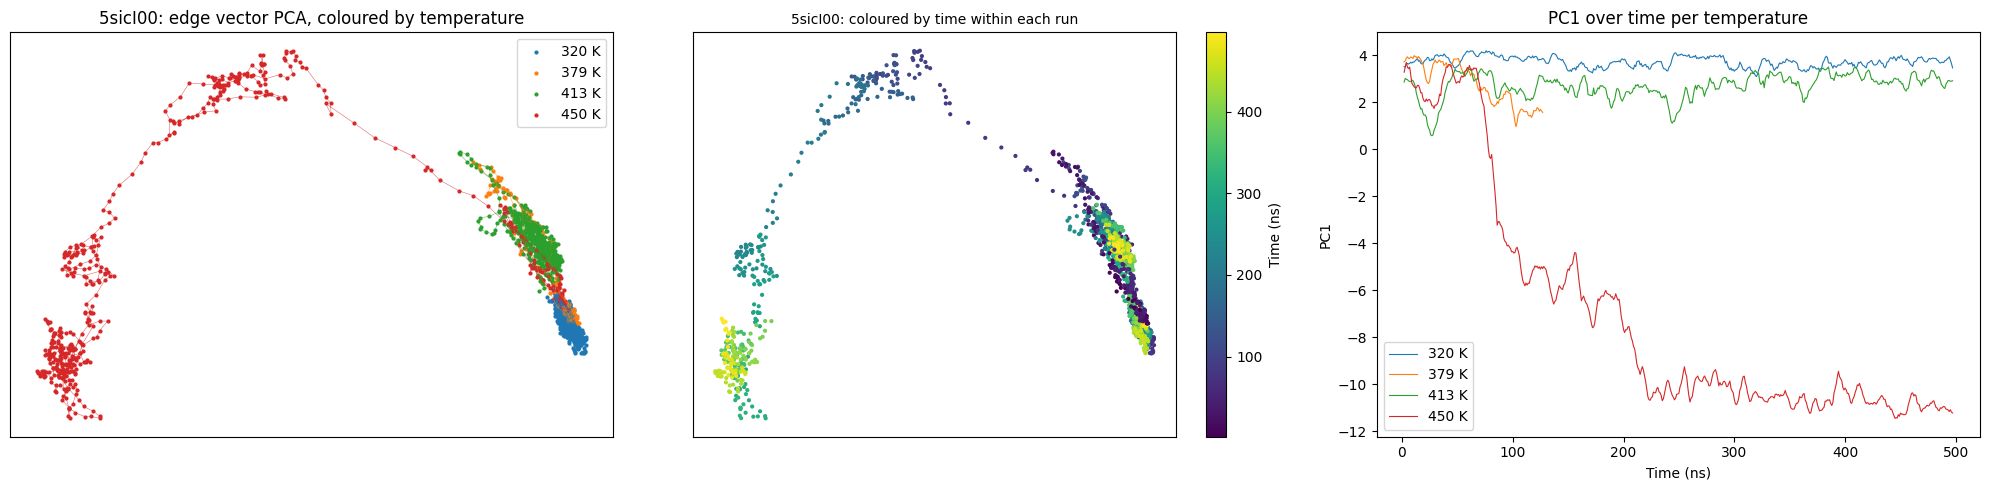

In [ ]:
MDCATH_WIDTH, MDCATH_OVERLAP = 5, 0.8
mstep = step_for(MDCATH_WIDTH, MDCATH_OVERLAP)
REPRESENTATION = "edge vector"   # or one of CENTRALITIES, e.g. "betweenness"


def features(coords, representation):
    # Full contact table here: constant columns are dropped only after stacking all temperatures,
    # so every temperature keeps the same columns.
    if representation == "edge vector":
        return contact_table(coords)
    return centrality_vectors(coords)[representation]

# for each temperature, compute the features and average over windows of 5 frames
# and record the temperature and time for each window
blocks, temps, times = [], [], []
for T, r in runs.items():
    W = window_mean(features(r["coords"], REPRESENTATION), MDCATH_WIDTH, mstep)
    blocks.append(W)
    temps.append(np.full(len(W), T))
    times.append(window_mean(r["time_ns"], MDCATH_WIDTH, mstep))
# stack all temperatures, drop constant columns, and do PCA to 2D
X_all = np.vstack(blocks)
temps, times = np.concatenate(temps), np.concatenate(times)
X_all = X_all[:, varying_columns(X_all)]
Y = PCA(n_components=2).fit_transform(X_all)

# color by temperature, time, and PC1 over time per temperature
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for T in runs:
    sel = temps == T
    axes[0].plot(Y[sel, 0], Y[sel, 1], lw=0.4, alpha=0.7)
    axes[0].scatter(Y[sel, 0], Y[sel, 1], s=4, label=f"{T} K")
axes[0].legend(); axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].set_title(f"{MDCATH_DOMAIN}: {REPRESENTATION} PCA, coloured by temperature")
plot_projection(axes[1], Y, times, f"{MDCATH_DOMAIN}: coloured by time within each run", "Time (ns)", connect=False)
for T in runs:
    sel = temps == T
    axes[2].plot(times[sel], Y[sel, 0], lw=0.8, label=f"{T} K")
axes[2].set_xlabel("Time (ns)"); axes[2].set_ylabel("PC1"); axes[2].legend()
axes[2].set_title("PC1 over time per temperature")
plt.tight_layout()
plt.show()

## 3. Proteins with several domains: whole vs. parts

### The idea

A **domain** is a part of a protein that folds into its own compact unit. 1k5n_A is the heavy chain of the human immune protein HLA-B\*27:09 (an MHC class I molecule, 276 residues). It has two parts: a **peptide-binding platform** (the α1 and α2 regions, roughly the first 180 residues, which together hold a short peptide in a groove) and an **α3 domain** (roughly the last 95 residues, an immunoglobulin-like domain). The platform itself has two halves (α1 and α2), so it can also be split into three parts. 16pk_A has two domains (visible as two blocks in its contact map).

Note: the ATLAS entry contains only chain A. In the crystal structure, the heavy chain is bound to a second protein (β2-microglobulin) and a peptide, which are missing here, so the α3 domain and the groove may move more than they would in the full complex.

In a multi-domain protein, two kinds of motion mix:
- **inside a domain**: local changes, like the 1a62_A transition,
- **between domains**: the domains moving relative to each other, e.g. a hinge opening and closing.

Projecting the whole protein mixes both. Projecting each part separately shows which part is responsible for a pattern.

### The parts

Every residue pair (column of the contact table) belongs to exactly one part:
- **intra-domain contacts of domain k**: both residues in domain k,
- **inter-domain contacts**: the residues are in different domains.

Each part is projected on its own, with the same windows and PCA as before.

### Domain boundaries

Two options:
- **Manual:** type the boundaries in `MANUAL_DOMAINS` (0-based positions in the CA list), e.g. from CATH. Check how ATLAS numbers the residues first: the ATLAS chain can be shorter than the PDB chain.
- **Automatic (default):** spectral clustering on the average contact map splits the residues into `n_domains` groups that have many contacts inside and few between. Isolated residues are smoothed out. Always compare the result with the contact map and, if possible, with CATH.

In [ ]:
from sklearn.cluster import SpectralClustering
from scipy.ndimage import median_filter

# how many parts; optionally the exact boundaries. with none, it finds them automatically
DOMAIN_SETUPS = {
    "1k5n_A": {"n_domains": 2, "manual": None},   # try 3 as well: alpha1 / alpha2 / alpha3
    "16pk_A": {"n_domains": 2, "manual": None},
}
# Manual example (0-based CA positions, end exclusive; a domain can have several segments):
# Approximate MHC class I boundaries, assuming the ATLAS chain starts at residue 1 (check the PDB file first):
# DOMAIN_SETUPS["1k5n_A"]["manual"] = {"platform (alpha1+alpha2)": [(0, 180)], "alpha3": [(180, 276)]}
# DOMAIN_SETUPS["1k5n_A"]["manual"] = {"alpha1": [(0, 90)], "alpha2": [(90, 180)], "alpha3": [(180, 276)]}


def contact_frequency(coords, threshold=CONTACT_THRESHOLD):
    return squareform(contact_table(coords, threshold).mean(axis=0))

# which residue belong to which part
def assign_domains(coords, n_domains, manual=None, smooth=9):
    """Domain label (0..n-1) per residue and the domain names."""
    N = coords.shape[1]
    if manual:
        labels = np.full(N, -1)
        for k, segments in enumerate(manual.values()):
            for start, end in segments:
                labels[start:end] = k
        if (labels < 0).any():
            print(f"warning: {(labels < 0).sum()} residues not in any domain; assigned to the nearest one")
            for r in np.flatnonzero(labels < 0):
                labels[r] = labels[np.flatnonzero(labels >= 0)[np.argmin(np.abs(np.flatnonzero(labels >= 0) - r))]]
        return labels, list(manual)
    freq = contact_frequency(coords)
    #automatically assign domains using spectral clustering on the contact frequency matrix
    labels = SpectralClustering(n_clusters=n_domains, affinity="precomputed",
                                random_state=RANDOM_STATE).fit_predict(freq + 1e-6)
    labels = median_filter(labels, size=smooth, mode="nearest")        # remove isolated residues
    order = {old: new for new, old in enumerate(dict.fromkeys(labels))}  # number domains along the chain
    labels = np.array([order[l] for l in labels])
    return labels, [f"domain {k}" for k in range(labels.max() + 1)]

# turns labels into text
def segments(labels, k):
    idx = np.flatnonzero(labels == k)
    breaks = np.flatnonzero(np.diff(idx) > 1)
    starts, ends = np.r_[idx[0], idx[breaks + 1]], np.r_[idx[breaks], idx[-1]]
    return ", ".join(f"{s}-{e}" for s, e in zip(starts, ends))


domains = {}
for p, setup in DOMAIN_SETUPS.items():
    if p not in data:
        continue
    labels, names = assign_domains(data[p]["coords"], setup["n_domains"], setup["manual"])
    domains[p] = {"labels": labels, "names": names}
    print(p)
    for k, name in enumerate(names):
        print(f"  {name}: residues {segments(labels, k)} ({(labels == k).sum()} residues)")

1k5n_A
  domain 0: residues 0-179 (180 residues)
  domain 1: residues 180-275 (96 residues)
16pk_A
  domain 0: residues 0-192, 404-414 (204 residues)
  domain 1: residues 193-403 (211 residues)


### Check the domains on the contact map

The average contact map with the domain of each residue as a coloured strip along both axes, and dashed lines at the boundaries.
Good domains look like dense square blocks on the diagonal with few contacts between them.

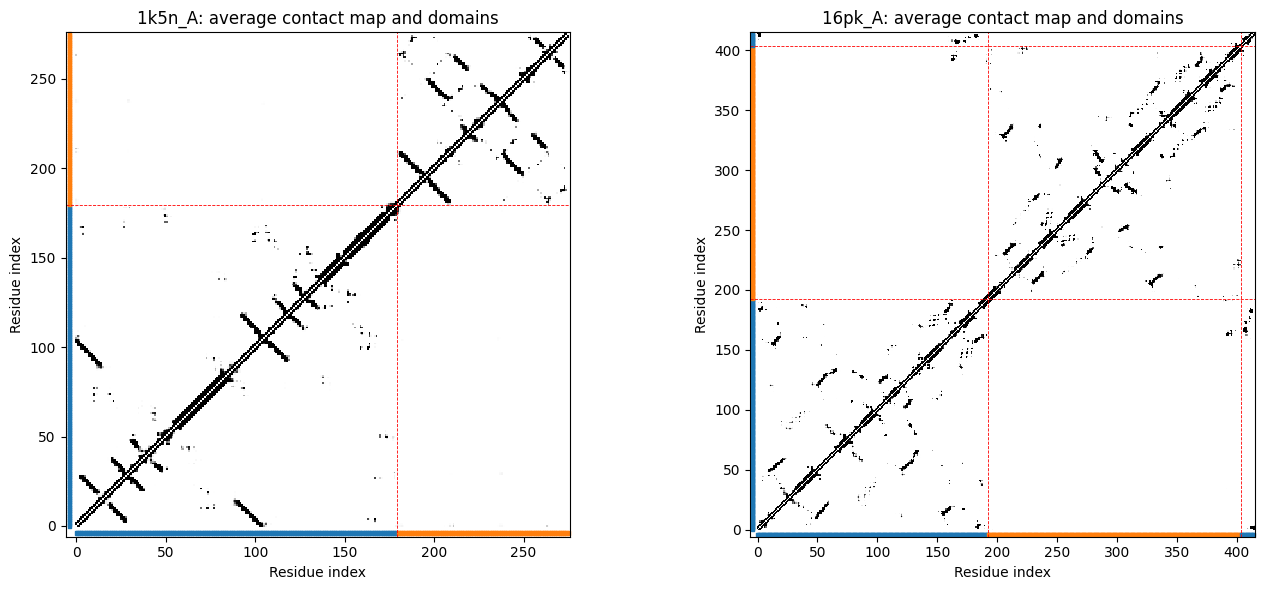

In [ ]:
fig, axes = plt.subplots(1, len(domains), figsize=(7 * len(domains), 6), squeeze=False)
for ax, (p, d) in zip(axes[0], domains.items()):
    labels = d["labels"]
    N = len(labels)
    ax.imshow(contact_frequency(data[p]["coords"]), origin="lower", cmap="Greys", vmin=0, vmax=1,
              interpolation="nearest")
    colours = plt.cm.tab10(labels)
    ax.scatter(np.arange(N), np.full(N, -4), c=colours, s=6, marker="s", clip_on=False)
    ax.scatter(np.full(N, -4), np.arange(N), c=colours, s=6, marker="s", clip_on=False)
    for b in np.flatnonzero(np.diff(labels)) + 0.5:
        ax.axvline(b, ls="--", lw=0.6, c="red"); ax.axhline(b, ls="--", lw=0.6, c="red")
    ax.set_xlim(-6, N); ax.set_ylim(-6, N)
    ax.set_title(f"{p}: average contact map and domains")
    ax.set_xlabel("Residue index"); ax.set_ylabel("Residue index")
plt.tight_layout()
plt.show()

### Projections: whole protein vs. each domain vs. between domains

One column per part. Top: PCA projection coloured by time. Bottom: PC1 over time.
The title shows how many contacts change in that part.

**How to read it**

- A transition visible in the whole protein **and** in one domain's own contacts happens inside that domain.
- A transition visible in the whole protein **and** in the inter-domain contacts, but not inside the domains, is a motion of the domains relative to each other (e.g. a hinge).
- A pattern that only shows up in one part (not in the whole) was drowned out by the rest of the protein: projecting parts separately reveals it.

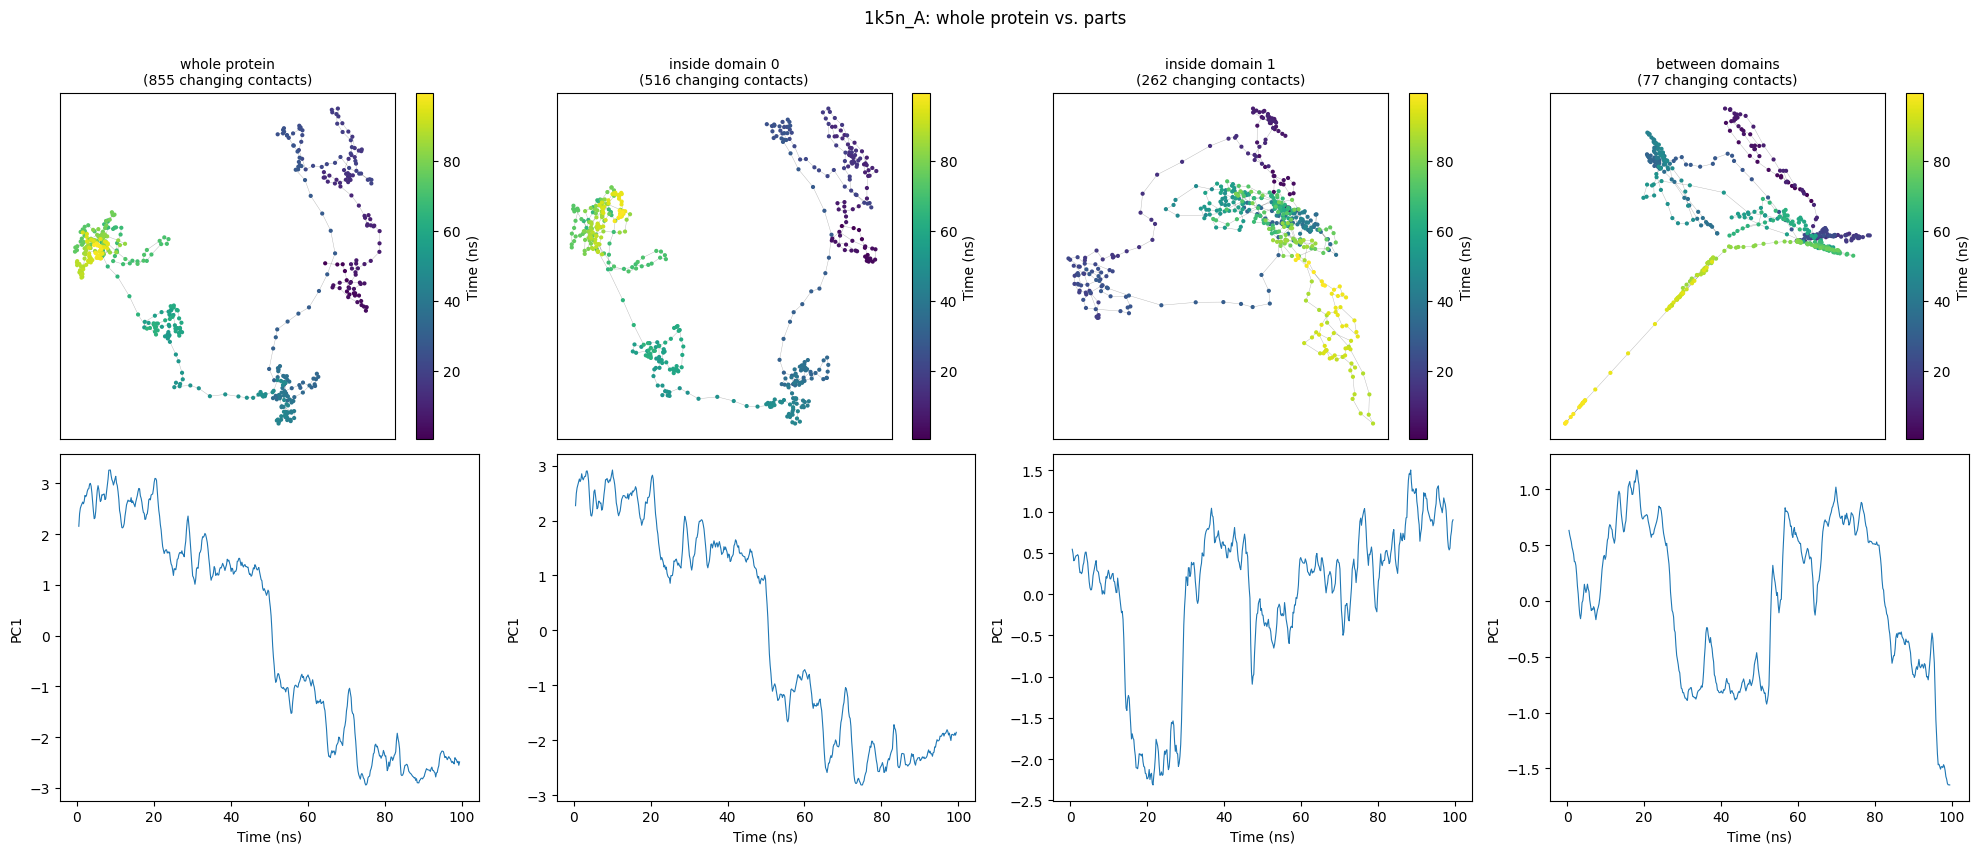

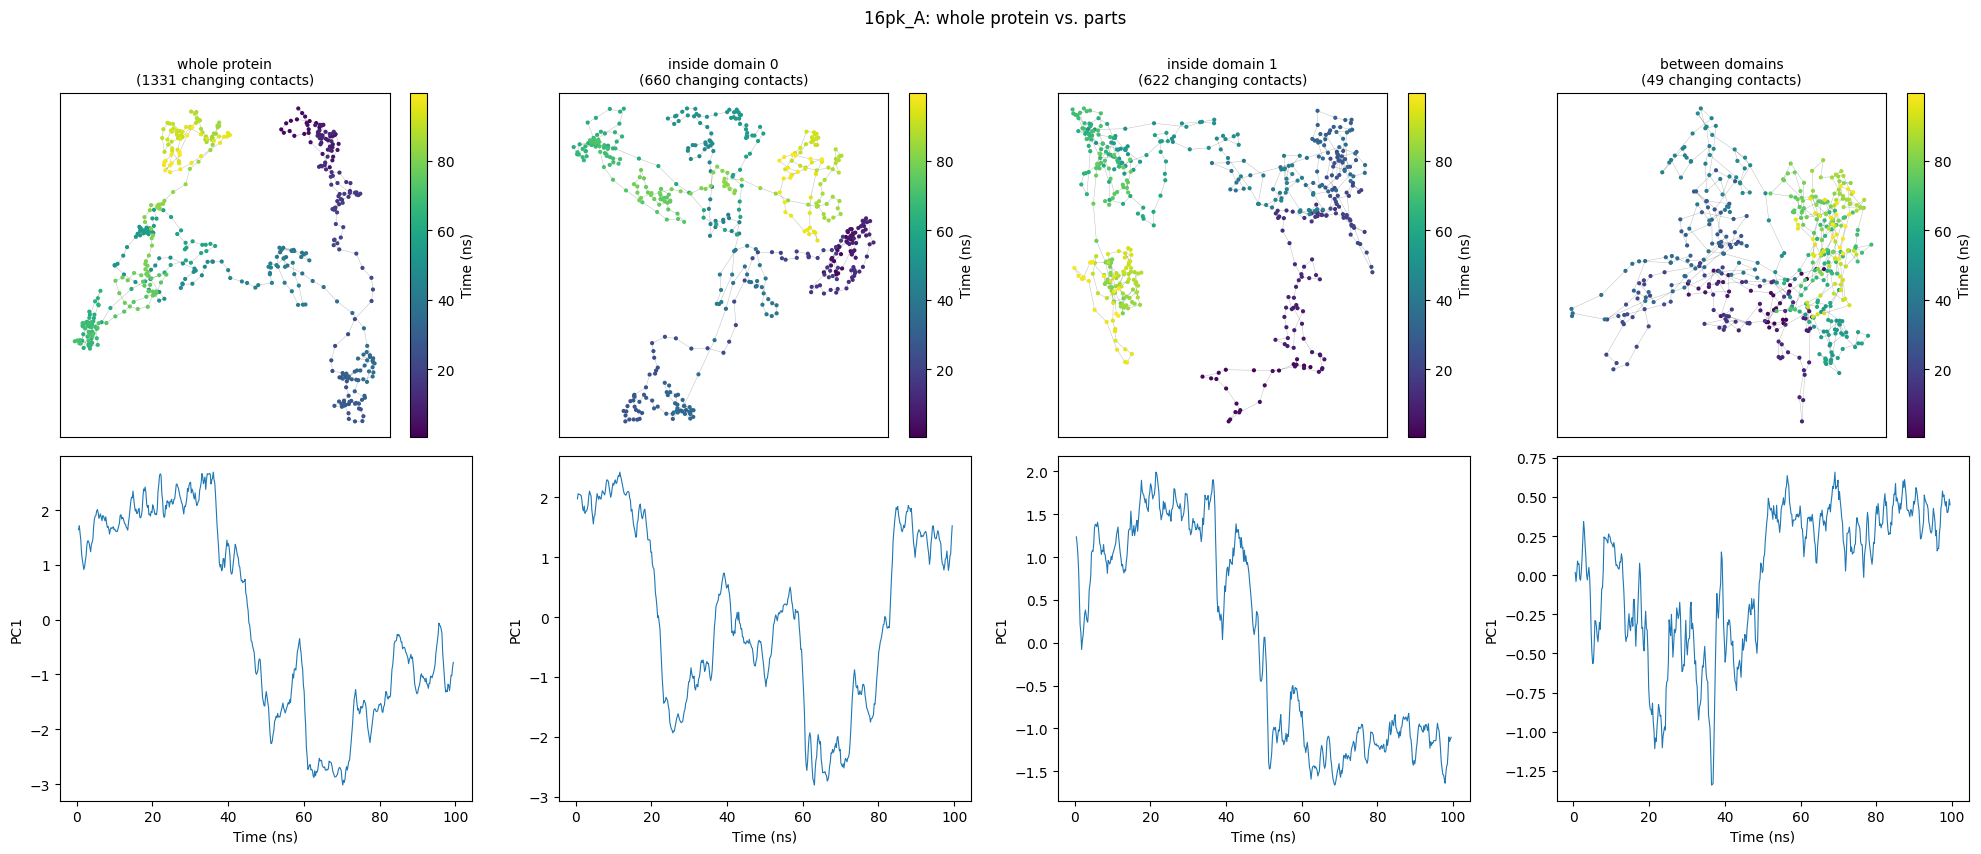

In [ ]:
# sorting contacts into parts
def part_masks(labels, names):
    N = len(labels)
    # I, J are two residues of every column in the contact table
    I, J = np.triu_indices(N, k=1)
    # domain numbers
    li, lj = labels[I], labels[J]
    masks = {"whole protein": np.ones(len(I), bool)}
    # a contact is inside domain k if both residues belong to that domain
    for k, name in enumerate(names):
        masks[f"inside {name}"] = (li == k) & (lj == k)
    masks["between domains"] = li != lj
    return masks

# one projection per part
def part_projections(p, labels, names):
    C = contact_table(data[p]["coords"])
    changing = varying_columns(C)
    t = window_mean(data[p]["time_ns"])
    results = {}
    for part, mask in part_masks(labels, names).items():
        # only take the changing contacts for PCA, and average over windows
        X = window_mean(C[:, mask & changing].astype(np.float32))
        keep = varying_columns(X)
        if keep.sum() < 2:
            print(f"{p}, {part}: fewer than 2 changing contacts, skipped")
            continue
        Y = PCA(n_components=2).fit_transform(X[:, keep])
        results[part] = {"Y": Y, "n_changing": int(keep.sum())}
    return results, t


for p, d in domains.items():
    results, t = part_projections(p, d["labels"], d["names"])
    fig, axes = plt.subplots(2, len(results), figsize=(5 * len(results), 8.5), squeeze=False)
    for col, (part, r) in enumerate(results.items()):
        plot_projection(axes[0, col], r["Y"], t, f"{part}\n({r['n_changing']} changing contacts)", "Time (ns)")
        axes[1, col].plot(t, r["Y"][:, 0], lw=0.8)
        axes[1, col].set_xlabel("Time (ns)"); axes[1, col].set_ylabel("PC1")
    fig.suptitle(f"{p}: whole protein vs. parts", y=1.0)
    plt.tight_layout()
    plt.show()

### Domain-level summary over time

Two simple readouts of how the domains move relative to each other:

- **Contacts between each pair of domains** over time: drops mean the domains move apart at that interface.
- **Distance between domain centres** (average CA position of each domain): an opening hinge shows up as a growing distance.

These help interpret the "between domains" projection above: a jump in its PC1 should coincide with a change here.

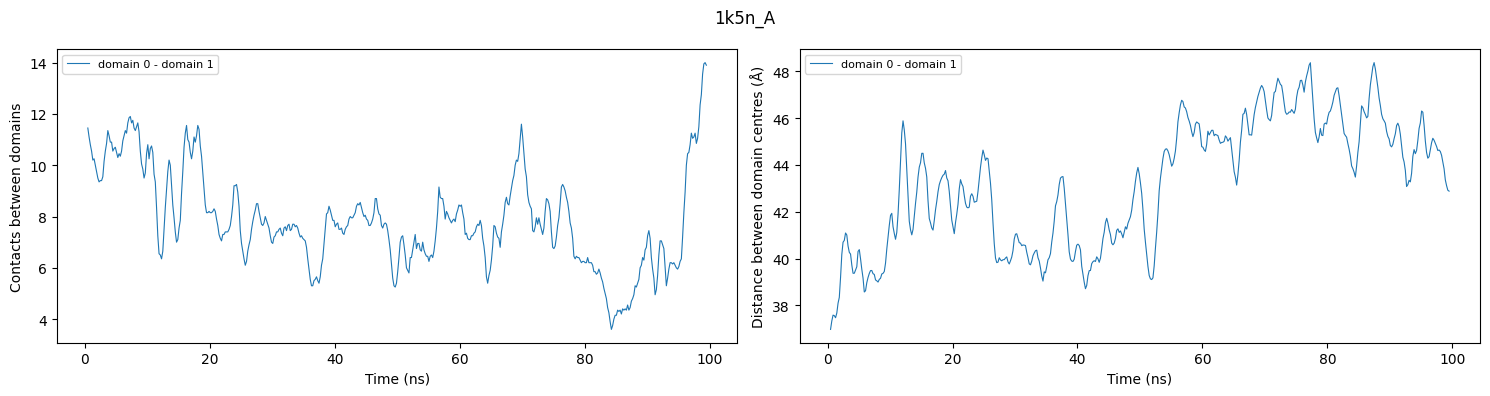

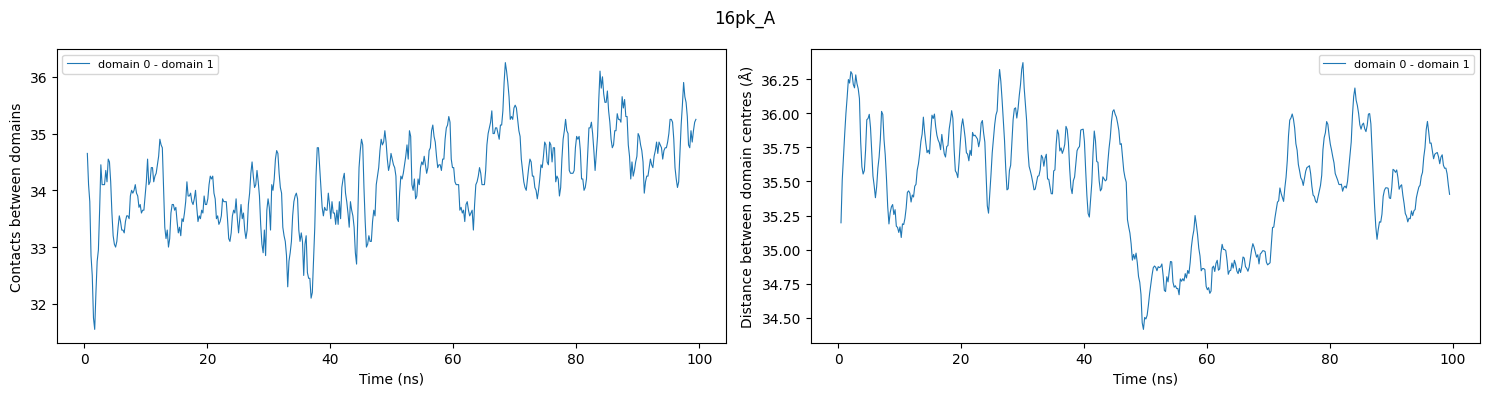

In [ ]:
for p, d in domains.items():
    labels, names = d["labels"], d["names"]
    coords, t_raw = data[p]["coords"], data[p]["time_ns"]
    K = labels.max() + 1
    pairs = [(a, b) for a in range(K) for b in range(a + 1, K)]

    fig, axes = plt.subplots(1, 2, figsize=(15, 4))
    t = window_mean(t_raw)
    for a, b in pairs:
        ia, ib = np.flatnonzero(labels == a), np.flatnonzero(labels == b)
        n_contacts = np.array([(np.linalg.norm(f[ia][:, None] - f[ib][None], axis=-1) < CONTACT_THRESHOLD).sum()
                               for f in coords])
        centre_dist = np.linalg.norm(coords[:, ia].mean(1) - coords[:, ib].mean(1), axis=-1)
        axes[0].plot(t, window_mean(n_contacts), lw=0.8, label=f"{names[a]} - {names[b]}")
        axes[1].plot(t, window_mean(centre_dist), lw=0.8, label=f"{names[a]} - {names[b]}")
    axes[0].set_ylabel("Contacts between domains"); axes[1].set_ylabel("Distance between domain centres (Å)")
    for ax in axes:
        ax.set_xlabel("Time (ns)"); ax.legend(fontsize=8)
    fig.suptitle(p)
    plt.tight_layout()
    plt.show()

### Centrality per domain (optional combination of 1 and 3)

Betweenness is a natural fit for multi-domain proteins: residues at the domain interfaces carry the shortest paths between domains.
This plot shows each residue's betweenness over time with the domain boundaries marked; a hinge motion should show up as a change in the interface residues.

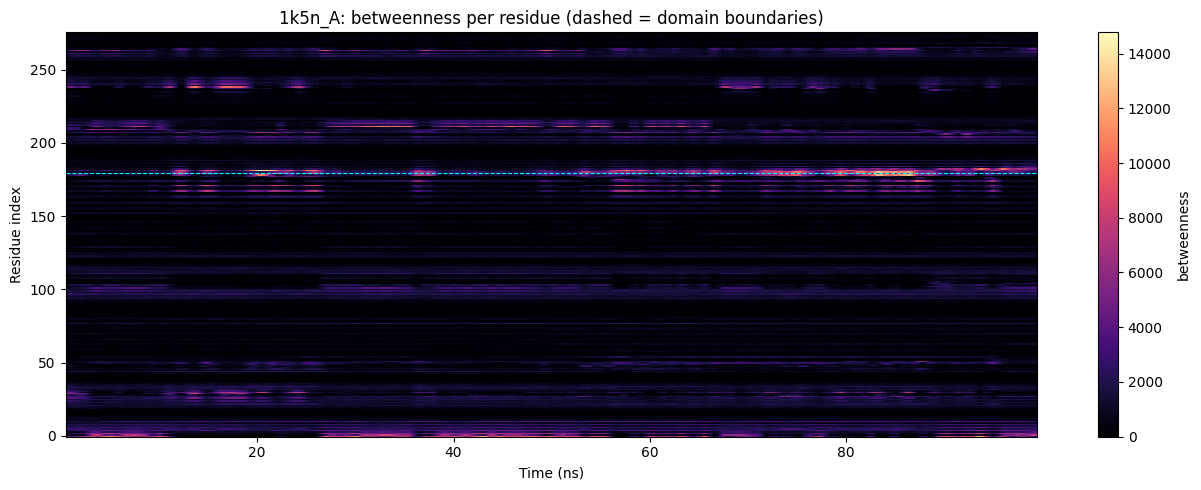

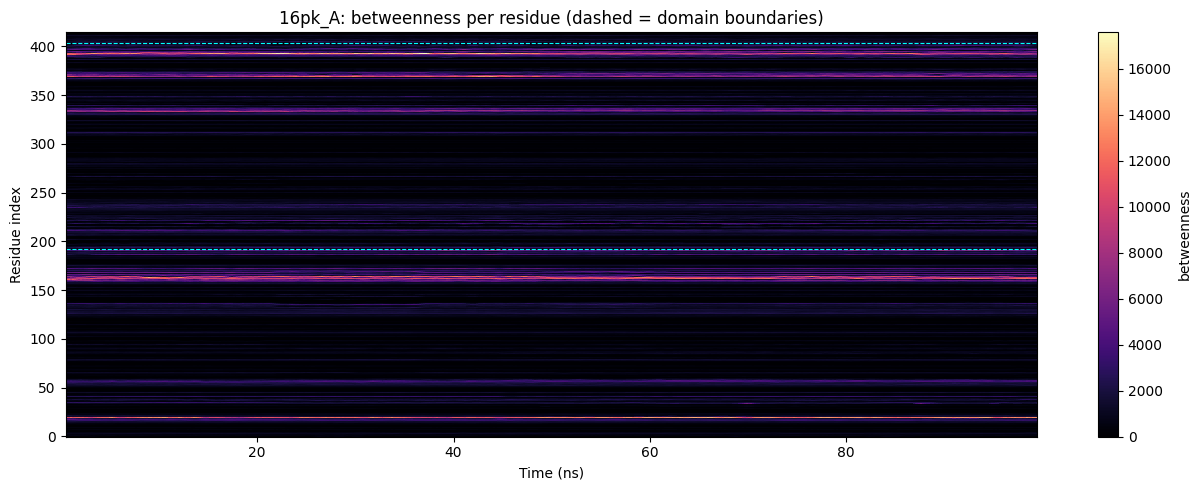

In [ ]:
for p, d in domains.items():
    labels = d["labels"]
    X = window_mean(cent[p]["betweenness"])
    t = window_mean(data[p]["time_ns"])
    N = X.shape[1]
    fig, ax = plt.subplots(figsize=(13, 5))
    im = ax.imshow(X.T, aspect="auto", origin="lower", cmap="magma",
                   extent=[t[0], t[-1], -0.5, N - 0.5], interpolation="nearest")
    for b in np.flatnonzero(np.diff(labels)) + 0.5:
        ax.axhline(b, ls="--", lw=0.8, c="cyan")
    ax.set_xlabel("Time (ns)"); ax.set_ylabel("Residue index")
    ax.set_title(f"{p}: betweenness per residue (dashed = domain boundaries)")
    plt.colorbar(im, ax=ax, label="betweenness")
    plt.tight_layout()
    plt.show()